## Hand Landmarks Model (Media Pipe)

In [1]:
%load_ext autoreload
%autoreload 2

In [6]:
from handspell.model_landmarks import create_landmarker, get_features
from handspell.model_landmarks_training import find_images, extract_features


In [3]:
landmarker = create_landmarker(
    hand_model_path="../models/hand_landmarker.task",
    min_hand_detection_confidence=0.1,
    min_hand_presence_confidence=0.1)

MediaPipe model: ../models/hand_landmarker.task


I0000 00:00:1792595104.775251 7442420 init-domain.cc:134] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792595104.789320 7442424 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792595104.796064 7442424 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [4]:
paths, labels = find_images("../data/dataset/D02_original_aslmnist")

In [5]:
paths

[PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A0.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A1.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A2.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A3.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A4.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A5.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A6.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A7.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A8.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A9.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_orig

In [ ]:
type(paths[0])

pathlib.PosixPath

In [7]:
labels

array([ 0,  0,  0, ..., 23, 23, 23], shape=(1680,))

In [8]:
type(landmarker)

mediapipe.tasks.python.vision.hand_landmarker.HandLandmarker

In [9]:
str(paths[0])

'../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A0.jpg'

In [10]:
features, landmarks, rgb = get_features(str(paths[0]), landmarker)

W0000 00:00:1792595105.519013 7442427 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


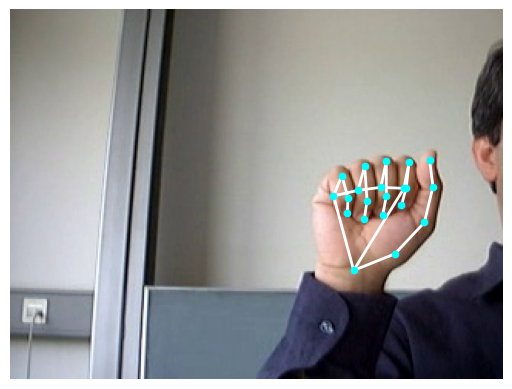

In [11]:
from handspell.model_landmarks import plot_landmarks

plot_landmarks(rgb_image=rgb, landmarks=landmarks);

In [12]:
features, failures = extract_features(paths, hand_model_path="../models/hand_landmarker.task")

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792595105.940971 7442463 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792595105.948144 7442467 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  0%|          | 0/1680 [00:00<?, ?it/s]

In [13]:
features

array([[ 0.        ,  0.        ,  0.        , ..., -0.06679054,
        -0.6563529 , -0.24982518],
       [ 0.        ,  0.        ,  0.        , ..., -0.04725572,
        -0.66391903, -0.25128052],
       [ 0.        ,  0.        ,  0.        , ..., -0.06668399,
        -0.6668268 , -0.24142633],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -0.05425099,
        -1.554621  ,  0.3548438 ],
       [ 0.        ,  0.        ,  0.        , ..., -0.06711246,
        -1.5724761 ,  0.35843658],
       [ 0.        ,  0.        ,  0.        , ..., -0.08791237,
        -1.5907835 ,  0.32328424]], shape=(1680, 63), dtype=float32)

In [14]:
failures

[]

## Images with no hands detected

In [ ]:
get_features(str("../data/dataset/D01_megadataset/O/A03_kaggle_asl__869.jpg"), landmarker)

In [3]:
from handspell.model_landmarks import INV_LABEL_MAP
from handspell.model_landmarks import plot_landmarks
import pandas as pd
# landmarks_df = pd.read_csv(
#     "../data/preprocessed/handlandmarks_d01megadataset.csv")

# # No hand detected
# landmarks_df["no_hand"] = landmarks_df['0'].isna()

# # Letter
# landmarks_df["letter"] = landmarks_df["letter_index"].replace(INV_LABEL_MAP)

# # Image shape
landmarks_df["image_shape"] = landmarks_df["image_path"].apply(lambda x: mpImage.create_from_file(x).numpy_view().shape)
landmarks_df["image_width"] = landmarks_df["image_shape"].apply(lambda x: x[0])
landmarks_df["image_height"] = landmarks_df["image_shape"].apply(lambda x: x[1])

landmarks_df["good"] = True
# Bad segmented dataset
landmarks_df.loc[
    (landmarks_df["dataset"] == 'A03_kaggle_asl') &
    (landmarks_df["image_width"] == 400), "good"] = False

# Too small images
landmarks_df.loc[(landmarks_df["image_width"] <= 50) &
                 (landmarks_df["image_height"] <= 50), "good"] = False

# No hand
landmarks_df.loc[landmarks_df.index.isin([55327,  55329,  55330,  55331,  55332,  55333,  55334,  55335,
        55336,  55337,  55338,  55340,  55341,  55342,  55343,  55346,
        55347]), "good"] = False

# landmarks_df.to_csv("../data/preprocessed/handlandmarks_d01megadataset_v1.csv")

# landmarks_df = pd.read_csv(
#     "../data/preprocessed/handlandmarks_d01megadataset_v1.csv")


landmarks_df.to_csv("../data/preprocessed/handlandmarks_d01megadataset_v1.csv")
landmarks_df.head()#

,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,5,6,7,...,letter_index,dataset,user,image_path,no_hand,letter,image_shape,image_width,image_height,good
0,0,0,0.0,0.0,0.0,0.542589,-0.123035,-0.099435,0.928112,-0.550039,...,0,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...,False,A,"(50, 50, 4)",50,50,False
1,1,1,0.0,0.0,0.0,0.531273,-0.145492,-0.093864,0.904783,-0.576911,...,0,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...,False,A,"(50, 50, 4)",50,50,False
2,2,2,0.0,0.0,0.0,0.549435,-0.172507,-0.104700,0.933805,-0.542889,...,0,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...,False,A,"(50, 50, 4)",50,50,False
3,3,3,0.0,0.0,0.0,0.058546,-0.293606,0.038537,0.351927,-0.601428,...,0,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...,False,A,"(50, 50, 4)",50,50,False
4,4,4,0.0,0.0,0.0,0.058546,-0.293606,0.038537,0.351927,-0.601428,...,0,A03_kaggle_asl,NaN,../data/dataset/D01_megadataset/A/A03_kaggle_a...,False,A,"(50, 50, 4)",50,50,False


In [55]:
landmarks_df["no_hand"].sum()

np.int64(27611)

In [56]:
landmarks_df.query("no_hand")[["dataset", "image_shape"]].value_counts()

dataset             image_shape  
A03_kaggle_asl      (200, 200, 4)    21461
                    (50, 50, 4)       5504
                    (400, 400, 4)      622
A04_mandalay_aslhg  (300, 300, 4)       20
B02_aslyset         (416, 416, 4)        4
Name: count, dtype: int64

In [92]:
landmarks_df.iloc[108903]

Unnamed: 0                                                108903
0                                                            NaN
1                                                            NaN
2                                                            NaN
3                                                            NaN
                                     ...                        
user                                                         NaN
image_path     ../data/dataset/D01_megadataset/R/A04_mandalay...
no_hand                                                     True
letter                                                         R
image_shape                                        (300, 300, 4)
Name: 108903, Length: 71, dtype: object

In [232]:
landmarks_df.query("dataset == 'A03_kaggle_asl'").groupby("image_shape")[["image_path"]].count()

,image_path
image_shape,
"(50, 50, 4)",33000
"(200, 200, 4)",72689
"(400, 400, 4)",2030


In [234]:
landmarks_df.query("dataset == 'A03_kaggle_asl'").groupby("image_shape")[["no_hand"]].sum()

,no_hand
image_shape,
"(50, 50, 4)",5504
"(200, 200, 4)",21461
"(400, 400, 4)",622


In [250]:
landmarks_df.query("dataset == 'A03_kaggle_asl'").groupby("image_shape")[["no_hand"]].mean()

,no_hand
image_shape,
"(50, 50, 4)",0.166788
"(200, 200, 4)",0.295244
"(400, 400, 4)",0.306404


In [4]:
ao3_probs = landmarks_df.query("no_hand & dataset == 'A03_kaggle_asl' & image_width==200")[["dataset", "letter", "image_shape", "image_path",]]
ao3_probs

,dataset,letter,image_shape,image_path
3002,A03_kaggle_asl,A,"(200, 200, 4)",../data/dataset/D01_megadataset/A/A03_kaggle_a...
3013,A03_kaggle_asl,A,"(200, 200, 4)",../data/dataset/D01_megadataset/A/A03_kaggle_a...
3024,A03_kaggle_asl,A,"(200, 200, 4)",../data/dataset/D01_megadataset/A/A03_kaggle_a...
3035,A03_kaggle_asl,A,"(200, 200, 4)",../data/dataset/D01_megadataset/A/A03_kaggle_a...
3046,A03_kaggle_asl,A,"(200, 200, 4)",../data/dataset/D01_megadataset/A/A03_kaggle_a...
...,...,...,...,...
135954,A03_kaggle_asl,Y,"(200, 200, 4)",../data/dataset/D01_megadataset/Y/A03_kaggle_a...
135955,A03_kaggle_asl,Y,"(200, 200, 4)",../data/dataset/D01_megadataset/Y/A03_kaggle_a...
135956,A03_kaggle_asl,Y,"(200, 200, 4)",../data/dataset/D01_megadataset/Y/A03_kaggle_a...
135957,A03_kaggle_asl,Y,"(200, 200, 4)",../data/dataset/D01_megadataset/Y/A03_kaggle_a...


In [9]:
ao3_probs["image_path"].values

<StringArray>
[        '../data/dataset/D01_megadataset/A/A03_kaggle_asl__A100.jpg',
         '../data/dataset/D01_megadataset/A/A03_kaggle_asl__A101.jpg',
         '../data/dataset/D01_megadataset/A/A03_kaggle_asl__A102.jpg',
         '../data/dataset/D01_megadataset/A/A03_kaggle_asl__A103.jpg',
         '../data/dataset/D01_megadataset/A/A03_kaggle_asl__A104.jpg',
         '../data/dataset/D01_megadataset/A/A03_kaggle_asl__A105.jpg',
         '../data/dataset/D01_megadataset/A/A03_kaggle_asl__A106.jpg',
         '../data/dataset/D01_megadataset/A/A03_kaggle_asl__A107.jpg',
         '../data/dataset/D01_megadataset/A/A03_kaggle_asl__A108.jpg',
        '../data/dataset/D01_megadataset/A/A03_kaggle_asl__A1082.jpg',
 ...
 '../data/dataset/D01_megadataset/Y/A03_kaggle_asl__Y2969_copy_2.jpg',
 '../data/dataset/D01_megadataset/Y/A03_kaggle_asl__Y2969_copy_3.jpg',
        '../data/dataset/D01_megadataset/Y/A03_kaggle_asl__Y2970.jpg',
   '../data/dataset/D01_megadataset/Y/A03_kaggle_asl__Y297

In [200]:
landmarks_df["image_path"].iloc[7]

'../data/dataset/D01_megadataset/A/A03_kaggle_asl__1002.jpg'

In [82]:
landmarks_df.query("no_hand & dataset == 'A04_mandalay_aslhg'")[["dataset", "letter", "image_shape", "image_path",]].index.values

array([ 55327,  55329,  55330,  55331,  55332,  55333,  55334,  55335,
        55336,  55337,  55338,  55340,  55341,  55342,  55343,  55346,
        55347, 108903, 108904, 108931])

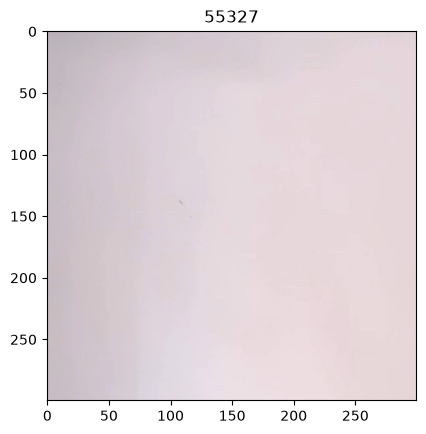

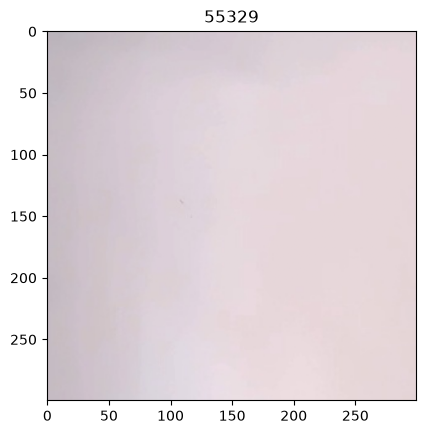

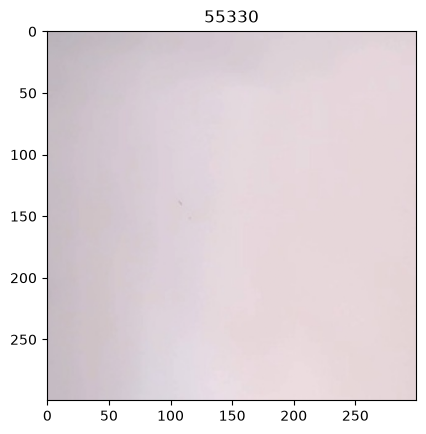

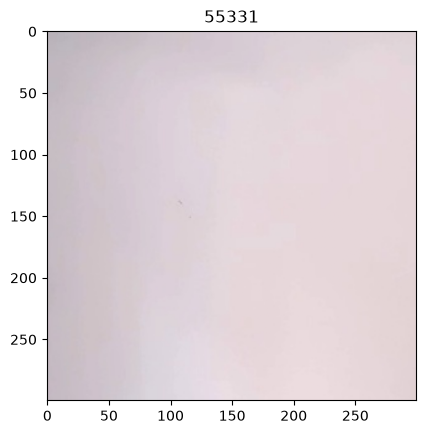

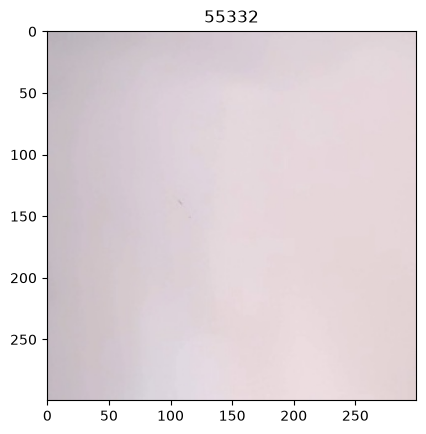

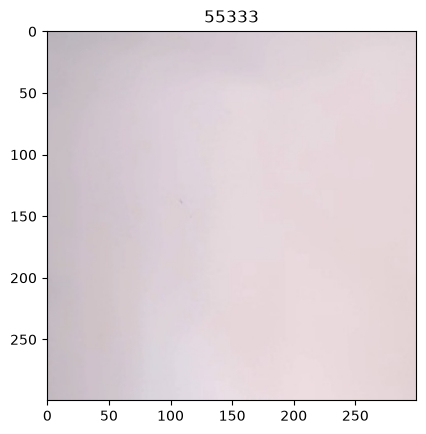

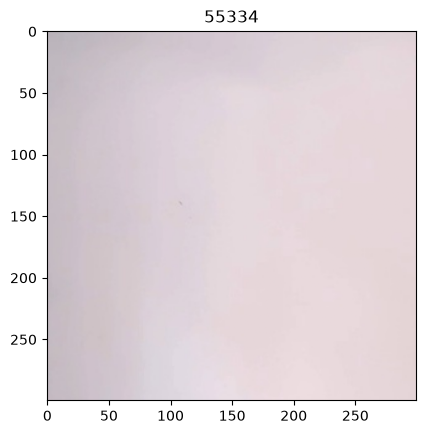

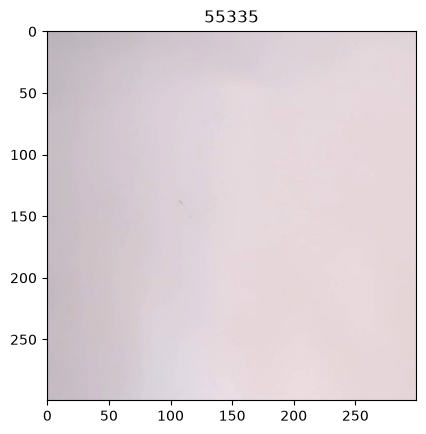

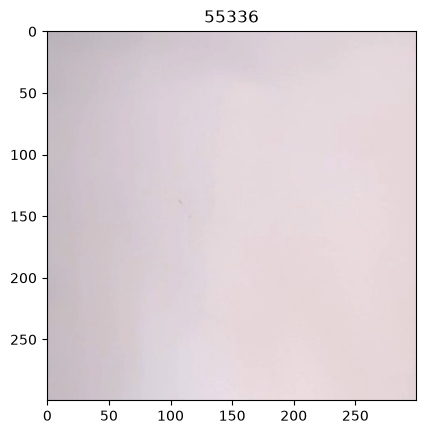

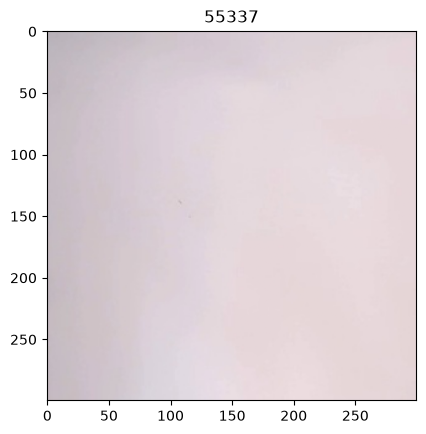

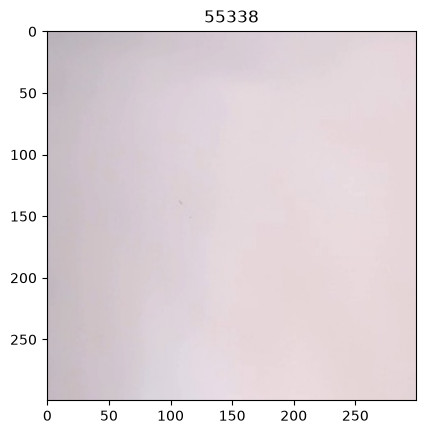

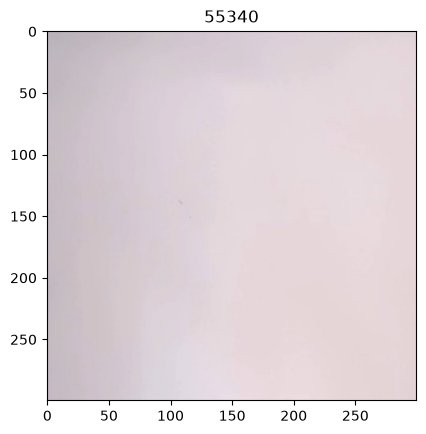

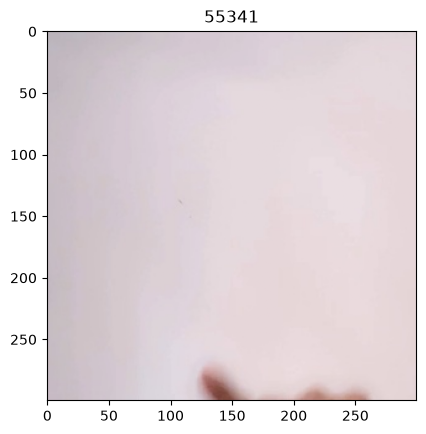

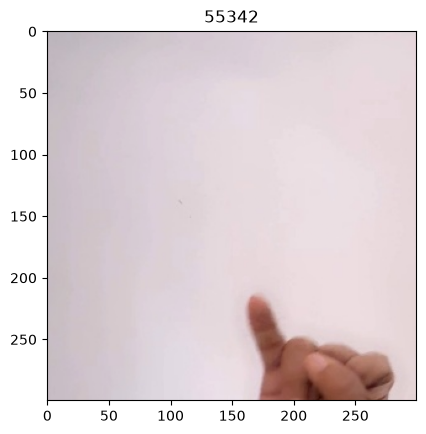

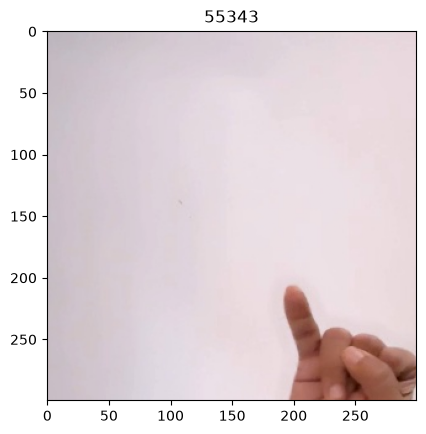

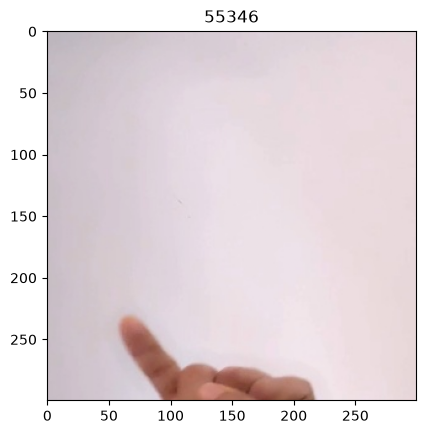

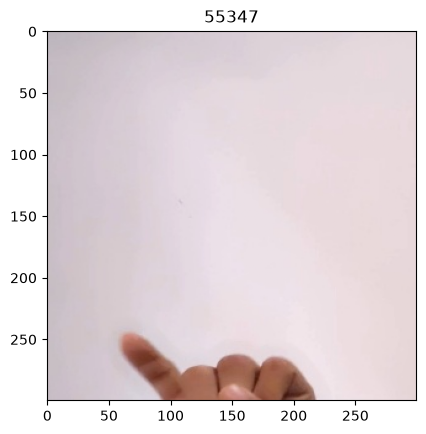

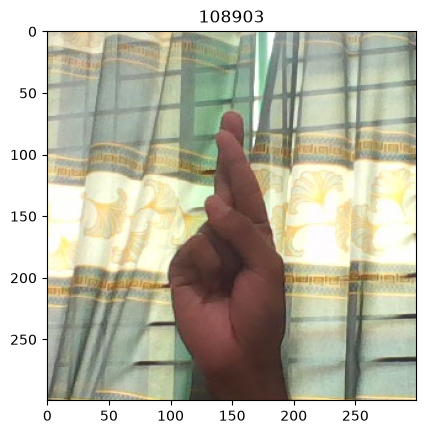

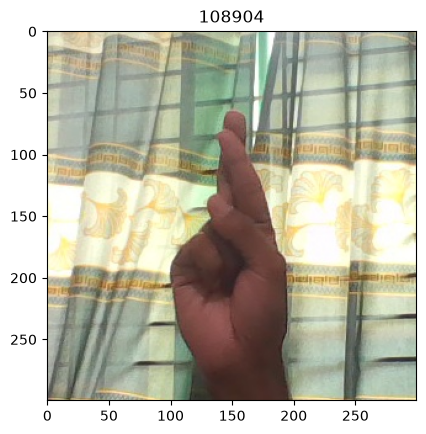

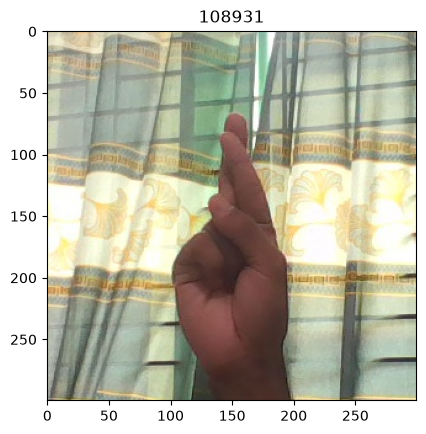

In [81]:
for i in landmarks_df.query("no_hand & dataset == 'A04_mandalay_aslhg'")[["dataset", "letter", "image_shape", "image_path",]].index.values:
    image_path = landmarks_df["image_path"].iloc[i]
    image = mpImage.create_from_file(image_path)
    _, ax = subplots()
    ax.imshow(image.numpy_view())
    ax.set_title(i)

In [41]:
landmarks_df["image_path"].apply(lambda x: mpImage.create_from_file(x).numpy_view().shape)

0    (50, 50, 4)
1    (50, 50, 4)
2    (50, 50, 4)
3    (50, 50, 4)
4    (50, 50, 4)
Name: image_path, dtype: object

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792615246.145410 7710792 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792615246.152577 7710792 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


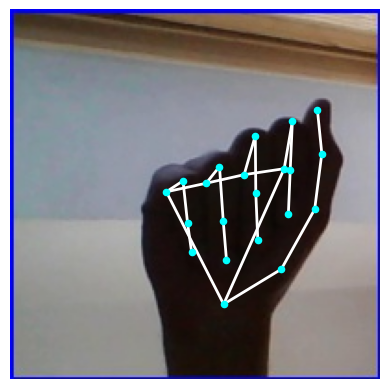

In [15]:
from matplotlib.pyplot import subplots
from mediapipe import Image as mpImage
image_path = landmarks_df["image_path"].iloc[3046]
image = mpImage.create_from_file(image_path)
result = create_landmarker(
    hand_model_path="../models/hand_landmarker.task",
    min_hand_detection_confidence=0,
    min_hand_presence_confidence=0).detect(image)
plot_landmarks(image.numpy_view(), result.hand_landmarks[0]);

In [16]:
cases = [[(0.5, 0.5), (0.5, 0.4), (0.5, 0.3), (0.5, 0.2), (0.5, 0.1)],
 [(0.4, 0.5), (0.4, 0.4), (0.4, 0.3), (0.4, 0.2), (0.4, 0.1)],
 [(0.3, 0.5), (0.3, 0.4), (0.3, 0.3), (0.3, 0.2), (0.3, 0.1)],
 [(0.2, 0.5), (0.2, 0.4), (0.2, 0.3), (0.2, 0.2), (0.2, 0.1)],
 [(0.1, 0.5), (0.1, 0.4), (0.1, 0.3), (0.1, 0.2), (0.1, 0.1)],
 [(0, 0.5), (0, 0.4), (0, 0.3), (0, 0.2), (0, 0.1)],
 ]

hand = []
for r in cases:
    v = []
    for c in r:
        landmarker = create_landmarker(
            hand_model_path="../models/hand_landmarker_latest.task",
            min_hand_detection_confidence=c[0],
            min_hand_presence_confidence=c[1])
        v += [len(landmarker.detect(image).hand_landmarks)]
    hand += [v]

MediaPipe model: ../models/hand_landmarker_latest.task


W0000 00:00:1792615255.974330 7710899 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792615255.985770 7710899 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792615256.171569 7710908 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


MediaPipe model: ../models/hand_landmarker_latest.task
MediaPipe model: ../models/hand_landmarker_latest.task


W0000 00:00:1792615256.179047 7710908 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792615256.332340 7710922 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792615256.337327 7710922 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


MediaPipe model: ../models/hand_landmarker_latest.task
MediaPipe model: ../models/hand_landmarker_latest.task


...

W0000 00:00:1792615260.790426 7711204 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792615260.794359 7711204 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


MediaPipe model: ../models/hand_landmarker_latest.task


W0000 00:00:1792615261.150258 7711217 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792615261.153100 7711219 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


MediaPipe model: ../models/hand_landmarker_latest.task


W0000 00:00:1792615261.504004 7711232 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792615261.507435 7711232 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [19]:
hand

[[0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0],
 [1, 1, 1, 1, 1],
 [1, 1, 1, 1, 1],
 [1, 1, 1, 1, 1]]

In [17]:
hand_135954 # should be 1 (backlit hand, landmarks good)

NameError: name 'hand_135954' is not defined

In [180]:
hand_127377  # should be 0 (has clear hand but landmarks are awful)

[[0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0],
 [1, 1, 1, 1, 1],
 [0, 0, 0, 1, 1],
 [0, 0, 0, 1, 1]]

In [177]:
hand_122163  # should be 1

[[0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0],
 [1, 1, 1, 1, 1],
 [1, 1, 1, 1, 1],
 [1, 1, 1, 1, 1]]

In [176]:
hand_122162 # should be 1

NameError: name 'hand_122162' is not defined

In [169]:
hand_96198 # should be 1

[[0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0],
 [1, 1, 1, 1, 1],
 [1, 1, 1, 1, 1],
 [1, 1, 1, 1, 1, 1]]

In [166]:
hand_55343 # should be 0

[[0, 0, 0, 1, 1],
 [0, 0, 0, 1, 1],
 [0, 0, 1, 1, 1],
 [0, 1, 1, 1, 1],
 [0, 0, 0, 1, 1],
 [0, 0, 1, 1, 1, 1]]

0.3 <= min_hand_detection_confidence <= 0.4
- 55346: `min_hand_detection_confidence  >= 0.3` (bad/no full hand); should be hand=0
- 55343: `min_hand_presence_confidence >= 0.3`; better `>=0.4`; (bad/no full hand); should be hand=0
- 96198: `min_hand_detection_confidence<= 2` (good hand, not detected, fine landmarks)

In [220]:
landmarker1 = create_landmarker(
    hand_model_path="../models/hand_landmarker_latest.task",
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5)

result = landmarker1.detect(image)
plot_landmarks(image.numpy_view(), result.hand_landmarks[0]);

MediaPipe model: ../models/hand_landmarker_latest.task


W0000 00:00:1792613433.252310 7690409 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792613433.259194 7690409 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


IndexError: list index out of range

#### Lower min_hand_presence_confidence


In [221]:
landmarker = create_landmarker(
    hand_model_path="../models/hand_landmarker.task",
    min_hand_detection_confidence=0,
    min_hand_presence_confidence=0.5)

result = landmarker.detect(image)
plot_landmarks(image.numpy_view(), result.hand_landmarks[0]);

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792613434.386168 7690434 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792613434.401911 7690434 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


IndexError: list index out of range

In [222]:
landmarker = create_landmarker(
    hand_model_path="../models/hand_landmarker.task",
    min_hand_detection_confidence=0.1,
    min_hand_presence_confidence=0.5)

result = landmarker.detect(image)
plot_landmarks(image.numpy_view(), result.hand_landmarks[0]);

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792613435.247891 7690453 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792613435.255916 7690456 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


IndexError: list index out of range

In [223]:
landmarker = create_landmarker(
    hand_model_path="../models/hand_landmarker.task",
    min_hand_detection_confidence=0.2,
    min_hand_presence_confidence=0.5)

result = landmarker.detect(image)
plot_landmarks(image.numpy_view(), result.hand_landmarks[0]);

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792613436.456202 7690470 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792613436.463299 7690473 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


IndexError: list index out of range

In [224]:
landmarker = create_landmarker(
    hand_model_path="../models/hand_landmarker.task",
    min_hand_detection_confidence=0,
    min_hand_presence_confidence=0.4)

result = landmarker.detect(image)
plot_landmarks(image.numpy_view(), result.hand_landmarks[0]);

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792613437.507938 7690490 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792613437.513648 7690490 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


IndexError: list index out of range

In [225]:
landmarker = create_landmarker(
    hand_model_path="../models/hand_landmarker.task",
    min_hand_detection_confidence=0,
    min_hand_presence_confidence=0.3)

result = landmarker.detect(image)
plot_landmarks(image.numpy_view(), result.hand_landmarks[0]);

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792613438.410021 7690510 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792613438.426995 7690508 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


IndexError: list index out of range

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792613439.259887 7690522 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792613439.266196 7690522 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


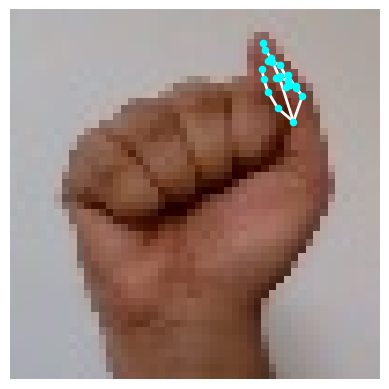

In [226]:
landmarker = create_landmarker(
    hand_model_path="../models/hand_landmarker.task",
    min_hand_detection_confidence=0,
    min_hand_presence_confidence=0.2)

result = landmarker.detect(image)
plot_landmarks(image.numpy_view(), result.hand_landmarks[0]);

In [ ]:
landmarks_df.query("dataset == 'A03_kaggle_asl' & image_width == 400")["image_path"].values[:4]
from matplotlib.pyplot import subplots
from mediapipe import Image as mpImage
image_path = landmarks_df["image_path"].iloc[6001]
image = mpImage.create_from_file(image_path)
result = create_landmarker(
    hand_model_path="../models/hand_landmarker.task",
    min_hand_detection_confidence=0,
    min_hand_presence_confidence=0).detect(image)
plot_landmarks(image.numpy_view(), result.hand_landmarks[0]);

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792614496.371132 7701477 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792614496.379510 7701477 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
Exception ignored in: <function HandLandmarker.__del__ at 0x17fee5760>
Traceback (most recent call last):
  File "/Users/delphinepessoa/code/notFonz/HandSpell/.venv/lib/python3.12/site-packages/mediapipe/tasks/python/vision/hand_landmarker.py", line 612, in __del__
    self.close()
  File "/Users/delphinepessoa/code/notFonz/HandSpell/.venv/lib/python3.12/site-packages/mediapipe/tasks/python/vision/hand_landmarker.py", line 588, in close
    self._lib.MpHandLandmarkerClose(self._handle)  # pyrefly: ignore[missing-attribute]
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/delphinepessoa/code/notFonz/HandSpell/.ven

In [ ]:
bad_indexes = [55327,  55329,  55330,  55331,  55332,  55333,  55334,  55335,
        55336,  55337,  55338,  55340,  55341,  55342,  55343,  55346,
        55347]
"dataset == 'A03_kaggle_asl' & image_width == 400" # bot cropped
image_width == 50 & image_height == 50  # too small

NameError: name 'image_width' is not defined